# Phase 2: Single-Sensor Autoregressive Baselines
### Univariate Linear Regression & LSTM Temporal Modeling

This notebook evaluates single-sensor predictive baselines:
1. Setup and data loading.
2. Sliding-window lag feature generation ($W=5$).
3. Autoregressive Linear Regression training, evaluation (MAE, RMSE), and predictions under missing data.
4. Deep temporal baseline: Long Short-Term Memory (LSTM) network with 1-hour lookback ($T=12$).


## Section 1: Environment Setup, Dependencies & System Configuration
We configure the runtime environment, set plotting styles, verify GPU hardware acceleration, and import fundamental scientific computing libraries (`numpy`, `pandas`, `matplotlib`).


In [4]:
#Day01_Traffic_Exploration.ipynb
# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

print("Setup complete ")


Setup complete 


In [ ]:
# Ingest METR-LA dataset (checks local directory or Colab environment)
import os
import zipfile
import pandas as pd

file_path = 'METR-LA.h5'
zip_path = 'METR-LA.h5.zip'

if not os.path.exists(file_path):
    if os.path.exists(zip_path):
        print(f"Extracting {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('.')
    elif os.path.exists('/content/METR-LA.h5.zip'):
        !unzip -o /content/METR-LA.h5.zip -d /content/
        file_path = '/content/METR-LA.h5'

if os.path.exists(file_path):
    df = pd.read_hdf(file_path)
elif os.path.exists('/content/METR-LA.h5'):
    df = pd.read_hdf('/content/METR-LA.h5')
else:
    # Fallback to local or downloaded copy
    df = pd.read_hdf('METR-LA.h5')

print("Dataset Shape (timesteps, sensors):", df.shape)
df.head()


## Section 4: Single-Sensor Classical Baseline (Lag Sequences & Linear Regression)
Before evaluating deep spatial models, we establish an autoregressive baseline using ordinary least squares (OLS) Linear Regression on sliding window lag features.

### 4.1 Sequence Generation Function
Construct historical feature windows $[x_{t-W}, \dots, x_{t-1}]$ to forecast target $y = x_t$.


In [ ]:
import numpy as np

def create_sequences(data, window_size=5):
    X = []
    y = []

    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])

    return np.array(X), np.array(y)


### 4.2 Dataset Partitioning (80% Train, 20% Test)


In [ ]:
sensor_id = df.columns[0]

series = df[sensor_id].values

X, y = create_sequences(series, window_size=5)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (34267, 5)
y shape: (34267,)


In [ ]:
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


### 4.3 Model Training & Performance Evaluation (MAE & RMSE)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)


MAE: 2.6761759967386207
RMSE: 6.50423250998594


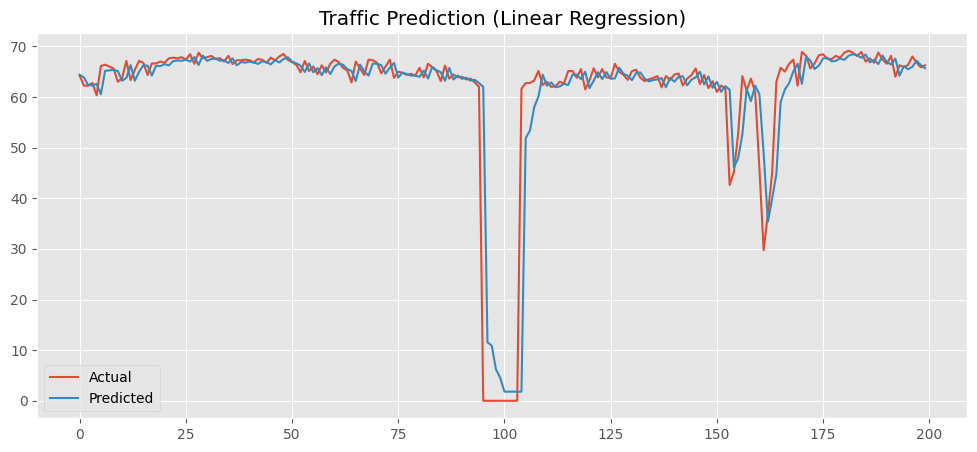

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(y_test[:200], label='Actual')
plt.plot(y_pred[:200], label='Predicted')
plt.legend()
plt.title("Traffic Prediction (Linear Regression)")
plt.show()


### 4.4 Evaluating Baseline Degradation under Missing Data


In [ ]:
series_missing = df_missing[sensor_id].ffill().bfill().values

X_m, y_m = create_sequences(series_missing, 5)

split = int(0.8 * len(X_m))

X_train_m, X_test_m = X_m[:split], X_m[split:]
y_train_m, y_test_m = y_m[:split], y_m[split:]

model_m = LinearRegression()
model_m.fit(X_train_m, y_train_m)

y_pred_m = model_m.predict(X_test_m)

mae_m = mean_absolute_error(y_test_m, y_pred_m)

print("MAE with missing data:", mae_m)


MAE with missing data: 2.2112763973326333


## Section 5: Single-Sensor Deep Learning Baseline (LSTM Model)
Long Short-Term Memory (LSTM) recurrent networks capture temporal dependencies across longer lookback horizons without vanishing gradients.

### 5.1 Deep Learning Dependencies & Data Normalization
We apply `MinMaxScaler` normalization to constrain values to $[0, 1]$ for stable gradient descent.


In [ ]:
!pip install tensorflow scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


In [ ]:
#training 1 sensor
sensor = df.columns[0]

series = df[sensor].values.reshape(-1,1)

print(series.shape)

scaler = MinMaxScaler()

series_scaled = scaler.fit_transform(series)

print(series_scaled.min())
print(series_scaled.max())


0.0
1.0


### 5.2 Sequence Construction (Lookback Horizon = 12 Steps / 1 Hour)


In [ ]:
def create_sequences(data, seq_length):

    X=[]
    y=[]

    for i in range(len(data)-seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])

    return np.array(X), np.array(y)

SEQ_LENGTH = 12

X,y = create_sequences(series_scaled,SEQ_LENGTH)

print(X.shape)
print(y.shape)

split = int(0.8*len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]


(34260, 12, 1)
(34260, 1)


### 5.3 LSTM Architecture & Training


In [ ]:
model = Sequential([
    LSTM(64,input_shape=(SEQ_LENGTH,1)),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)


Epoch 1/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0233 - val_loss: 0.0115
Epoch 2/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0121 - val_loss: 0.0083
Epoch 3/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0106 - val_loss: 0.0073
Epoch 4/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0102 - val_loss: 0.0063
Epoch 5/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0099 - val_loss: 0.0088
Epoch 6/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0099 - val_loss: 0.0060
Epoch 7/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0099 - val_loss: 0.0069
Epoch 8/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0099 - val_loss: 0.0070
Epoch 9/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0099 - val_loss: 0.0061
Epoch 10/10
771/771 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0099 - val_loss: 0.0066


### 5.4 Training History & Convergence Curve


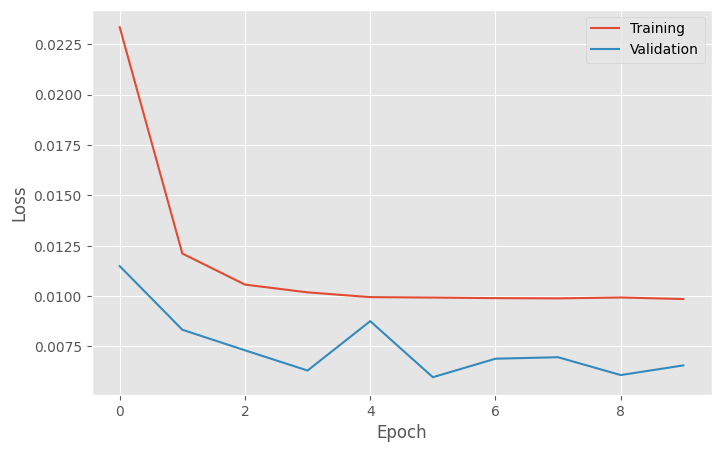

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"],label="Training")
plt.plot(history.history["val_loss"],label="Validation")

plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


### 5.5 Model Evaluation & Out-of-Sample Predictions


In [ ]:
pred = model.predict(X_test)

pred = scaler.inverse_transform(pred)

actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual,pred)

rmse = np.sqrt(mean_squared_error(actual,pred))

print("MAE:",mae)
print("RMSE:",rmse)


MAE: 2.7485092174525363
RMSE: 6.517260906158092


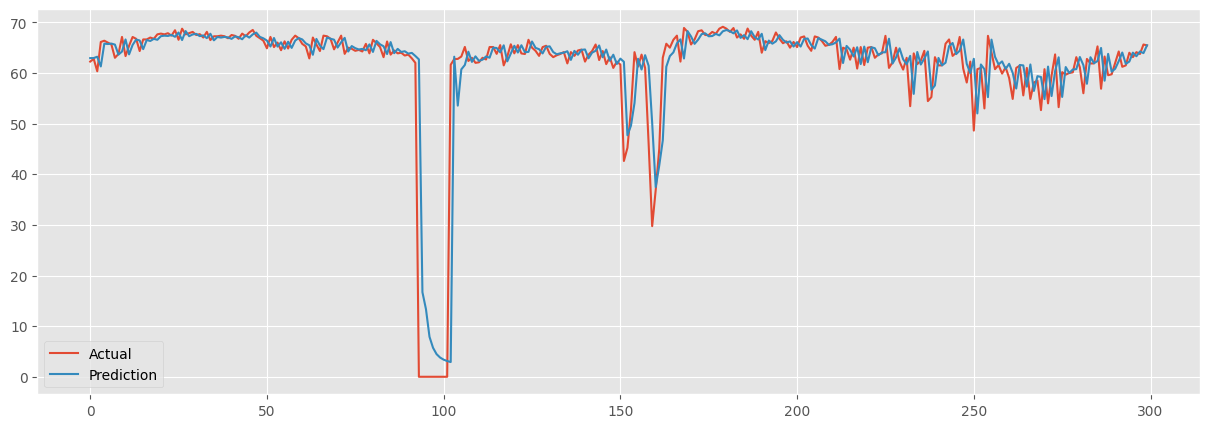

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(actual[:300],label="Actual")
plt.plot(pred[:300],label="Prediction")

plt.legend()

plt.show()
